# Washington Housing Analysis - Exploratory Data Analysis

## Introduction

In [1]:
# Import pandas, numpy, and matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# seaborn is a data visualization library built on matplotlib
import seaborn as sns

# set the plotting style
sns.set_style("whitegrid")

# Model preprocessing
from sklearn.preprocessing import StandardScaler

# Modeling
import statsmodels.formula.api as smf
import statsmodels.api as sm

# Model metrics and analysis
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from statsmodels.stats.anova import anova_lm

In [2]:
from pathlib import Path

DATA_DIR = Path('../data')

final_dataset_path = DATA_DIR / 'housing_final.csv'

df = pd.read_csv(final_dataset_path  , dtype = {'county_fips': str})

## Inspect data

In [3]:
df.head()

,county_fips,county,wsdot_region,year,average_zhvi,median_income,unemployment_rate,mortgage_rate_mean
0,53001,Adams County,Eastern,2015,139521.505277,46564,7.0,3.851
1,53001,Adams County,Eastern,2016,145808.702755,47554,6.9,3.654
2,53001,Adams County,Eastern,2017,155473.557623,48131,6.2,3.990
3,53001,Adams County,Eastern,2018,170273.632919,49142,6.0,4.545
4,53001,Adams County,Eastern,2019,184500.979061,48294,6.3,3.936


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 390 entries, 0 to 389
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   county_fips         390 non-null    str    
 1   county              390 non-null    str    
 2   wsdot_region        390 non-null    str    
 3   year                390 non-null    int64  
 4   average_zhvi        389 non-null    float64
 5   median_income       390 non-null    int64  
 6   unemployment_rate   390 non-null    float64
 7   mortgage_rate_mean  390 non-null    float64
dtypes: float64(3), int64(2), str(3)
memory usage: 35.4 KB


## Visualize Home Value

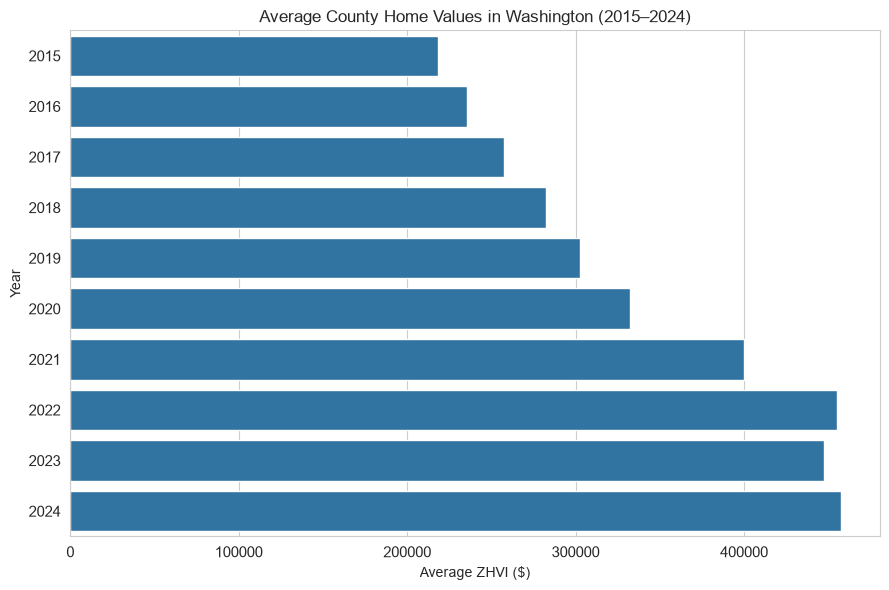

In [5]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=df,
    x="average_zhvi",
    y="year",
    orient="h",
    errorbar=None
)

plt.title("Average County Home Values in Washington (2015–2024)")
plt.xlabel("Average ZHVI ($)")
plt.ylabel("Year")

plt.tick_params(labelsize=11)
plt.tight_layout()
plt.show()

### Visualize housing price tend using lineplot

In [6]:
yearly_zhvi = (
    df.groupby("year", as_index=False)
    .agg(avg_zhvi=("average_zhvi", "mean"))
)

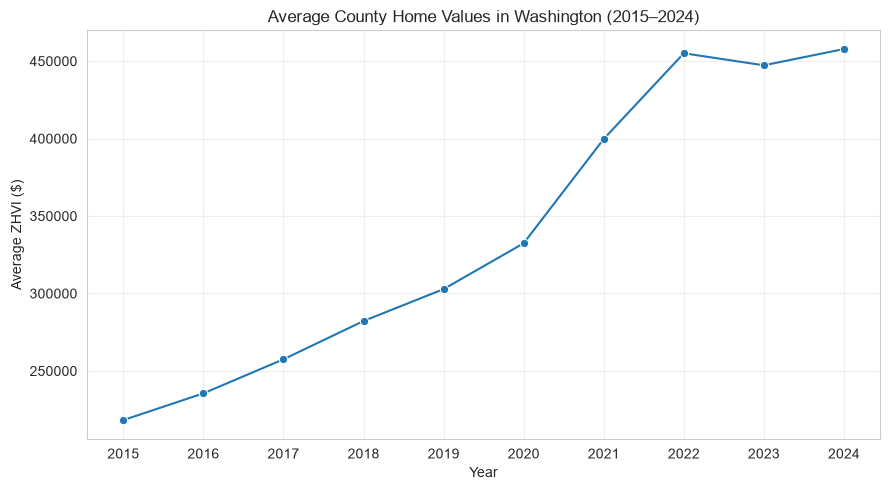

In [7]:
plt.figure(figsize=(9, 5))

sns.lineplot(
    data=yearly_zhvi,
    x="year",
    y="avg_zhvi",
    marker="o"
)

plt.title("Average County Home Values in Washington (2015–2024)")
plt.xlabel("Year")
plt.ylabel("Average ZHVI ($)")
plt.xticks(range(2015, 2025))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Average Housing Value by Region

In [8]:
regional_zhvi = df.groupby(["wsdot_region", "year"], as_index=False).agg(avg_zhvi=("average_zhvi", "mean"),county_count=("average_zhvi", "count"))
    
regional_zhvi.head()

,wsdot_region,year,avg_zhvi,county_count
0,Eastern,2015,163554.264188,7
1,Eastern,2016,174236.006616,7
2,Eastern,2017,185735.314008,7
3,Eastern,2018,200998.245453,7
4,Eastern,2019,220211.716912,7


In [9]:
regional_zhvi.info()

<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   wsdot_region  60 non-null     str    
 1   year          60 non-null     int64  
 2   avg_zhvi      60 non-null     float64
 3   county_count  60 non-null     int64  
dtypes: float64(1), int64(2), str(1)
memory usage: 2.6 KB


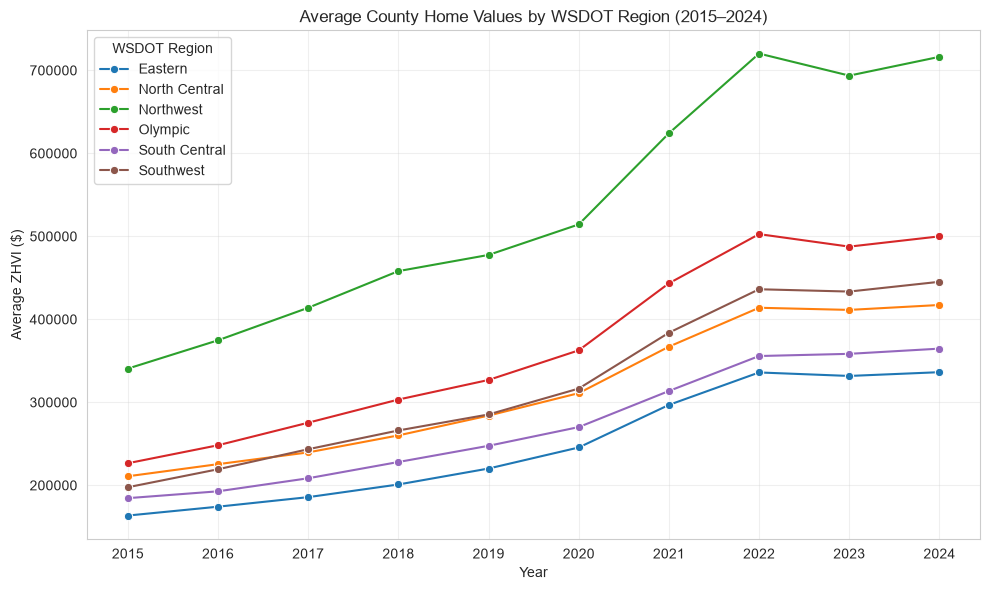

In [11]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=regional_zhvi,
    x="year",
    y="avg_zhvi",
    hue="wsdot_region",
    marker="o"
)

plt.title("Average County Home Values by WSDOT Region (2015–2024)")
plt.xlabel("Year")
plt.ylabel("Average ZHVI ($)")
plt.xticks(range(2015, 2025))
plt.legend(title="WSDOT Region")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Annual Housing Value Appreciation by Region

### Distribution of home values

## Home Value relationship with median household income